# Qatar Import Trade Data Lakehouse (2017–2024)

**Dataset:** CEPII BACI HS17  
**Architecture:** Bronze → Silver → Gold  
**Focus:** Qatar's imports from 2017 to 2024

This notebook documents the ingestion, cleaning, dimensional modeling,
and analysis of Qatar's international merchandise imports.

In [1]:
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Both imports successful!")

NumPy: 2.5.3
Pandas: 3.0.6
Both imports successful!


## 1. Bronze Layer — Raw Data Ingestion

The Bronze layer stores the original BACI HS17 trade records
from 2017 to 2024.

All source columns are preserved as strings, and ingestion
metadata is added to support traceability and auditing.

In [4]:
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = Path.cwd().resolve()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

LAKEHOUSE_DIR = BASE_DIR / "lakehouse"

con = duckdb.connect(str(LAKEHOUSE_DIR / "connection.duckdb"))
con.execute("LOAD ducklake;")

catalog_path = (LAKEHOUSE_DIR / "catalog.ducklake").as_posix()
storage_path = (LAKEHOUSE_DIR / "storage").as_posix() + "/"

con.execute(f"""
    ATTACH 'ducklake:{catalog_path}' AS lake
    (DATA_PATH '{storage_path}');
""")

print("Connected to DuckLake successfully!")

Connected to DuckLake successfully!


In [5]:
bronze_summary = con.execute("""
    SELECT
        source_name,
        SUM(input_row_count) AS total_rows
    FROM lake.bronze.load_log
    GROUP BY source_name
    ORDER BY source_name
""").df()

display(bronze_summary)

print(
    "Total Bronze records:",
    f"{bronze_summary['total_rows'].sum():,}"
)

,source_name,total_rows
0,BACI_HS17_Y2017_V202601.csv,9948845.0
1,BACI_HS17_Y2018_V202601.csv,10802500.0
2,BACI_HS17_Y2019_V202601.csv,11210131.0
3,BACI_HS17_Y2020_V202601.csv,10985158.0
4,BACI_HS17_Y2021_V202601.csv,11598685.0
5,BACI_HS17_Y2022_V202601.csv,11703117.0
6,BACI_HS17_Y2023_V202601.csv,11781215.0
7,BACI_HS17_Y2024_V202601.csv,11177570.0


Total Bronze records: 89,207,221.0


## 2. Silver Layer — Data Cleaning and Quality Validation

The Silver layer filters the Bronze dataset to Qatar imports
(importer code 634) from 2017 to 2024.

It validates years, country codes, product codes, trade values,
and quantities, and checks for duplicate business keys.

Missing quantities are retained as NULL because the corresponding
trade values are still useful for analysis. Invalid records are
stored in a quarantine table.

The quality report summarizes the cleaning results.

In [6]:
silver_quality = con.execute("""
    SELECT
        metric,
        metric_value
    FROM lake.silver.quality_report
    ORDER BY metric
""").df()

display(silver_quality)

,metric,metric_value
0,bronze_qatar_rows,467811
1,bronze_total_rows,89207221
2,duplicate_rows,0
3,null_key_rows,0
4,quarantine_rows,0
5,silver_duplicate_keys,0
6,silver_null_quantity,11278
7,silver_valid_rows,467811


## 3. Gold Layer — Dimensional Modeling

The Gold layer organizes Qatar's cleaned import records into a star schema
containing one fact table and three dimension tables.

**Fact table:** `fact_imports`

**Dimension tables:**
- `dim_year`: Year information.
- `dim_exporter`: Exporter country names and ISO3 codes.
- `dim_product`: HS17 product codes and descriptions.

**Fact table grain:** One row represents the import of one HS17 product
from one exporter country into Qatar during one year.

The fact table stores trade value and quantity, with foreign keys
referencing the three dimensions.

In [7]:
gold_counts = con.execute("""
    SELECT 'dim_year' AS table_name, COUNT(*) AS row_count
    FROM lake.gold.dim_year

    UNION ALL

    SELECT 'dim_exporter', COUNT(*)
    FROM lake.gold.dim_exporter

    UNION ALL

    SELECT 'dim_product', COUNT(*)
    FROM lake.gold.dim_product

    UNION ALL

    SELECT 'fact_imports', COUNT(*)
    FROM lake.gold.fact_imports
""").df()

display(gold_counts)

,table_name,row_count
0,dim_year,8
1,dim_exporter,169
2,dim_product,5173
3,fact_imports,467811


## 4. Data Analysis — Gold Layer

All four analytical questions are answered using Gold-layer tables only.

### Question 1: How did Qatar's total import value change from 2017 to 2024?

This query calculates Qatar's annual import value by summing trade
values from the Gold fact table and joining the year dimension.

,year,total_import_value
0,2017,22647187.65
1,2018,28491365.70
2,2019,30582883.76
3,2020,30357095.12
4,2021,32628451.07
5,2022,39673403.22
6,2023,37813395.55
7,2024,37134679.73


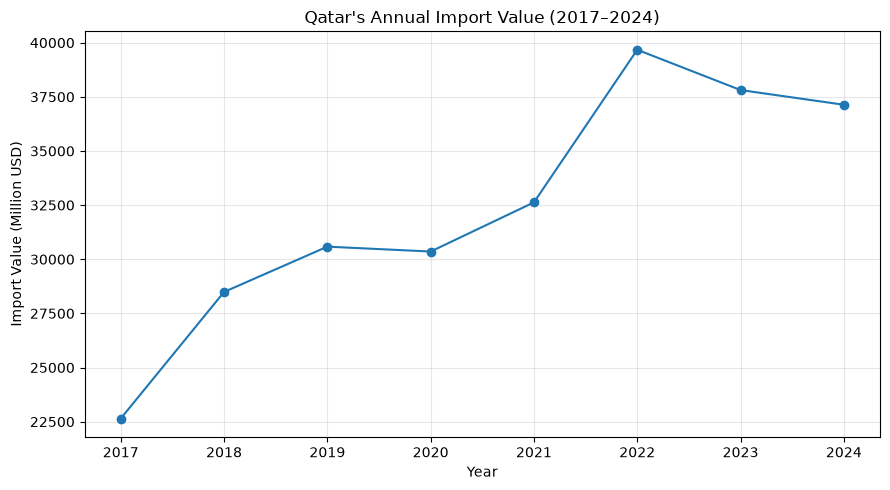

In [8]:
# Question 1: Qatar's annual import value
q1 = con.execute("""
    SELECT
        y.year,
        ROUND(SUM(f.trade_value), 2) AS total_import_value
    FROM lake.gold.fact_imports f
    JOIN lake.gold.dim_year y
        ON f.year_key = y.year_key
    GROUP BY y.year
    ORDER BY y.year
""").df()

display(q1)

# Visualization 1
plt.figure(figsize=(9, 5))
plt.plot(
    q1["year"],
    q1["total_import_value"] / 1000,
    marker="o"
)

plt.title("Qatar's Annual Import Value (2017–2024)")
plt.xlabel("Year")
plt.ylabel("Import Value (Million USD)")
plt.xticks(q1["year"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Question 2: Which 10 countries supplied Qatar with the highest import value?

This query identifies the ten largest exporter countries supplying Qatar
between 2017 and 2024, ranked by their total trade value.

It joins the Gold fact table with the exporter dimension to display
country names instead of numeric country codes.

,exporter_country,total_import_value
0,China,29446689.57
1,USA,26697133.70
2,United Kingdom,22096966.94
3,France,16375844.08
4,United Arab Emirates,13320660.64
5,India,13309943.14
6,Germany,13133309.75
7,Italy,12313490.03
8,Oman,10382016.68
9,Japan,9363254.58


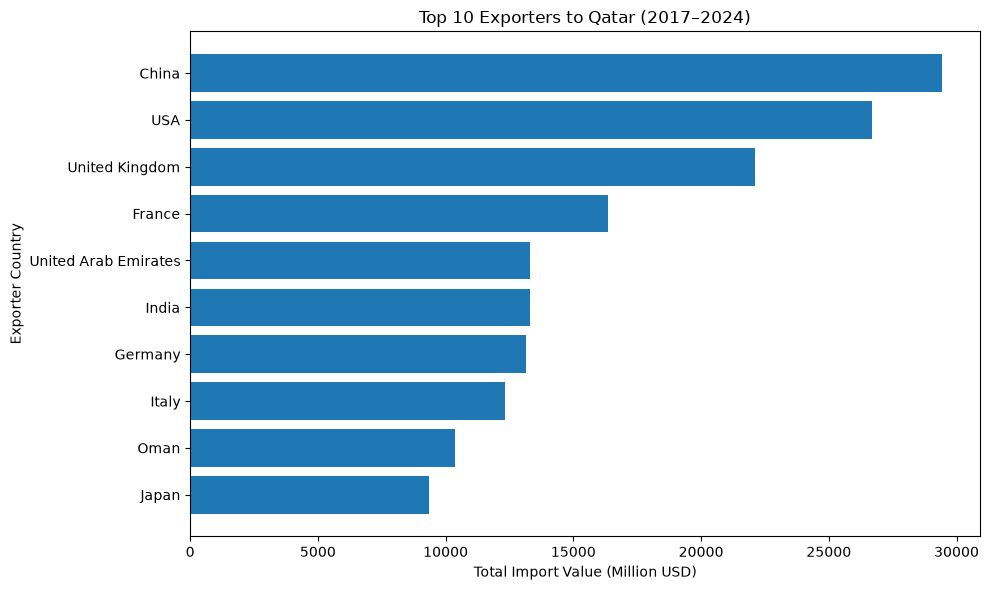

In [9]:
# Question 2: Top 10 exporter countries
q2 = con.execute("""
    SELECT
        e.country_name AS exporter_country,
        ROUND(SUM(f.trade_value), 2) AS total_import_value
    FROM lake.gold.fact_imports f
    JOIN lake.gold.dim_exporter e
        ON f.exporter_key = e.exporter_key
    GROUP BY e.exporter_key, e.country_name
    ORDER BY total_import_value DESC
    LIMIT 10
""").df()

display(q2)

# Visualization 2: Horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    q2["exporter_country"],
    q2["total_import_value"] / 1000
)

plt.gca().invert_yaxis()
plt.title("Top 10 Exporters to Qatar (2017–2024)")
plt.xlabel("Total Import Value (Million USD)")
plt.ylabel("Exporter Country")
plt.tight_layout()
plt.show()